In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from loguru import logger
from langgraph.checkpoint.memory import InMemorySaver

# 1.构建子图
# 1.1声明子图的状态
class SubgraphState(TypedDict):
    raw_text: str  # 未清洗的文本
    stripped_text: str   # 去除收尾的空格
    punctuated_text: str # 句尾添加句号

# 1.2 声明子图的结点
# 去除空格的结点
def subgraph_strip_node(state: SubgraphState) -> SubgraphState:
    raw_text = state["raw_text"]
    stripped_text = raw_text.strip()
    logger.info("调用子图中的strip结点")
    return {
        "stripped_text": stripped_text
    }

# 1.3 添加句号的结点
def subgraph_punctuated_node(state: SubgraphState) -> SubgraphState:
    stripped_text = state["stripped_text"]
    punctuated_text = stripped_text + '。'
    logger.info("调用子图中的punctuated结点")
    return {
        "punctuated_text": punctuated_text
    }

# 1.4 构建子图
builder = StateGraph(state_schema = SubgraphState)
builder.add_node("subgraph_strip_node", subgraph_strip_node)
builder.add_node("subgraph_punctuated_node", subgraph_punctuated_node)
builder.add_edge(START, "subgraph_strip_node")
builder.add_edge("subgraph_strip_node", "subgraph_punctuated_node")
builder.add_edge("subgraph_punctuated_node", END)

subgraph = builder.compile()

2026-10-30 12:17:18.397 | INFO     | __main__:subgraph_strip_node:18 - 调用子图中的strip结点
2026-10-30 12:17:18.398 | INFO     | __main__:subgraph_punctuated_node:27 - 调用子图中的punctuated结点


{'input_text': '  langgraph666   ', 'cleared_text': 'langgraph666。'}


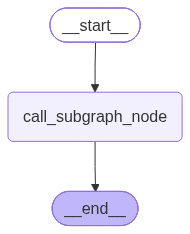

In [2]:
# 2.构建父图
# 2.1 声明状态
class ParentState(TypedDict):
    input_text: str
    cleared_text: str

# 2.2 声明结点 调用子图结点
def call_subgraph_node(state: ParentState) -> ParentState:
    input_text = state["input_text"]
    res = subgraph.invoke({"raw_text": input_text})
    cleared_text = res["punctuated_text"]
    return {
        "cleared_text": cleared_text
    }

# 2.3 构建父图
parent_builder = StateGraph(state_schema = ParentState)
parent_builder.add_node("call_subgraph_node", call_subgraph_node)
parent_builder.add_edge(START, "call_subgraph_node")
parent_builder.add_edge("call_subgraph_node", END)

# 添加检查点信息
checkpointer = InMemorySaver()
parent_graph = parent_builder.compile(checkpointer = checkpointer)

# 添加检查点之后必须填写config
config = {
    "configurable": {
        "thread_id": "111"
    }
}

# 2.4 调用父图 内部函数会调用子图
res = parent_graph.invoke({"input_text": "  langgraph666   "}, config = config)
print(res)

from IPython.display import display
display(parent_graph)

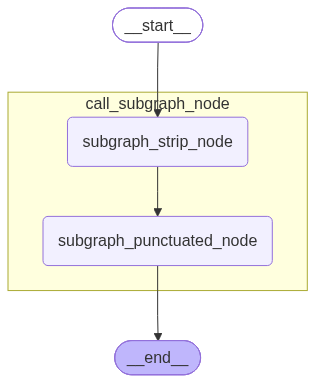

In [3]:
from IPython.display import display, Image
display(
    Image(
        parent_graph.get_graph(xray = True).draw_mermaid_png()
    )
)

In [4]:
# 获取父图历史检查点列表
histories = list(parent_graph.get_state_history(config = config))
print(histories)

[StateSnapshot(values={'input_text': '  langgraph666   ', 'cleared_text': 'langgraph666。'}, next=(), config={'configurable': {'thread_id': '111', 'checkpoint_ns': '', 'checkpoint_id': '1f1d418c-b850-656d-8001-2f158f01f339'}}, metadata={'source': 'loop', 'step': 1, 'parents': {}}, created_at='2026-10-30T04:17:18.399212+00:00', parent_config={'configurable': {'thread_id': '111', 'checkpoint_ns': '', 'checkpoint_id': '1f1d418c-b848-6557-8000-b058101ce78c'}}, tasks=(), interrupts=()), StateSnapshot(values={'input_text': '  langgraph666   '}, next=('call_subgraph_node',), config={'configurable': {'thread_id': '111', 'checkpoint_ns': '', 'checkpoint_id': '1f1d418c-b848-6557-8000-b058101ce78c'}}, metadata={'source': 'loop', 'step': 0, 'parents': {}}, created_at='2026-10-30T04:17:18.395932+00:00', parent_config={'configurable': {'thread_id': '111', 'checkpoint_ns': '', 'checkpoint_id': '1f1d418c-b846-686a-bfff-fad3947ff02e'}}, tasks=(PregelTask(id='d5a70ff7-5c3f-4131-0a7d-b0c4482088f6', name='

In [6]:
# 获取父图检查点配置
parent_config = histories[-2].config
parent_config

{'configurable': {'thread_id': '111',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1d418c-b848-6557-8000-b058101ce78c'}}

In [7]:
# 展开子图快照
parent_graph.get_state(config=parent_config, subgraphs=True)

StateSnapshot(values={'input_text': '  langgraph666   '}, next=('call_subgraph_node',), config={'configurable': {'thread_id': '111', 'checkpoint_ns': '', 'checkpoint_id': '1f1d418c-b848-6557-8000-b058101ce78c'}}, metadata={'source': 'loop', 'step': 0, 'parents': {}}, created_at='2026-10-30T04:17:18.395932+00:00', parent_config={'configurable': {'thread_id': '111', 'checkpoint_ns': '', 'checkpoint_id': '1f1d418c-b846-686a-bfff-fad3947ff02e'}}, tasks=(PregelTask(id='d5a70ff7-5c3f-4131-0a7d-b0c4482088f6', name='call_subgraph_node', path=('__pregel_pull', 'call_subgraph_node'), error=None, interrupts=(), state=StateSnapshot(values={'raw_text': '  langgraph666   ', 'stripped_text': 'langgraph666', 'punctuated_text': 'langgraph666。'}, next=(), config={'configurable': {'thread_id': '111', 'checkpoint_ns': 'call_subgraph_node:d5a70ff7-5c3f-4131-0a7d-b0c4482088f6', 'checkpoint_id': '1f1d418c-b84e-6aa9-8002-f58f88426d96', 'checkpoint_map': {'': '1f1d418c-b848-6557-8000-b058101ce78c', 'call_subgr

In [10]:
# 获取子图检查点配置
subgraph_config = histories[-2].tasks[0].state
subgraph_config

{'configurable': {'thread_id': '111',
  'checkpoint_ns': 'call_subgraph_node:d5a70ff7-5c3f-4131-0a7d-b0c4482088f6'}}

In [9]:
# 查看完整子图检查点快照列表 在检查点记录是 是使用checkpoint_ns来区别不同的子图
list(parent_graph.get_state_history(config=subgraph_config))

[StateSnapshot(values={'raw_text': '  langgraph666   ', 'stripped_text': 'langgraph666', 'punctuated_text': 'langgraph666。'}, next=(), config={'configurable': {'thread_id': '111', 'checkpoint_ns': 'call_subgraph_node:d5a70ff7-5c3f-4131-0a7d-b0c4482088f6', 'checkpoint_id': '1f1d418c-b84e-6aa9-8002-f58f88426d96', 'checkpoint_map': {'': '1f1d418c-b848-6557-8000-b058101ce78c', 'call_subgraph_node:d5a70ff7-5c3f-4131-0a7d-b0c4482088f6': '1f1d418c-b84e-6aa9-8002-f58f88426d96'}}}, metadata={'source': 'loop', 'step': 2, 'parents': {'': '1f1d418c-b848-6557-8000-b058101ce78c'}}, created_at='2026-10-30T04:17:18.398526+00:00', parent_config={'configurable': {'thread_id': '111', 'checkpoint_ns': 'call_subgraph_node:d5a70ff7-5c3f-4131-0a7d-b0c4482088f6', 'checkpoint_id': '1f1d418c-b84c-6ee4-8001-cd5bfd2cf879', 'checkpoint_map': {'': '1f1d418c-b848-6557-8000-b058101ce78c', 'call_subgraph_node:d5a70ff7-5c3f-4131-0a7d-b0c4482088f6': '1f1d418c-b84c-6ee4-8001-cd5bfd2cf879'}}}, tasks=(), interrupts=()),
 S